In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from nba_api.stats.static.teams import find_team_by_abbreviation

find_team_by_abbreviation("NYK")["id"]


{'id': 1610612752,
 'full_name': 'New York Knicks',
 'abbreviation': 'NYK',
 'nickname': 'Knicks',
 'city': 'New York',
 'state': 'New York',
 'year_founded': 1946}

In [8]:
from nba_api.stats.endpoints.teamgamelog import TeamGameLog

df = TeamGameLog(
    team_id="1610612752",
    season="2025-26",
    season_type_all_star="Regular Season",
).get_data_frames()[0]

df[::-1].reset_index(drop=True)


,Team_ID,Game_ID,GAME_DATE,MATCHUP,WL,W,L,W_PCT,MIN,FGM,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS
0,1610612752,0022500003,"OCT 22, 2025",NYK vs. CLE,W,1,0,1.000,240,37,...,0.861,9,39,48,22,8,4,13,23,119
1,1610612752,0022500018,"OCT 24, 2025",NYK vs. BOS,W,2,0,1.000,240,33,...,0.880,21,32,53,23,7,4,15,17,105
2,1610612752,0022500108,"OCT 26, 2025",NYK @ MIA,L,2,1,0.667,240,38,...,0.762,16,36,52,23,9,3,15,24,107
3,1610612752,0022500125,"OCT 28, 2025",NYK @ MIL,L,2,2,0.500,240,39,...,0.870,17,28,45,24,9,2,13,21,111
4,1610612752,0022500023,"OCT 31, 2025",NYK @ CHI,L,2,3,0.400,240,45,...,0.739,12,27,39,27,3,5,12,25,125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,1610612752,0022501123,"APR 03, 2026",NYK vs. CHI,W,50,28,0.641,240,48,...,0.893,13,41,54,30,11,3,8,21,136
78,1610612752,0022501143,"APR 06, 2026",NYK @ ATL,W,51,28,0.646,240,42,...,0.765,12,35,47,29,9,7,15,14,108
79,1610612752,0022501168,"APR 09, 2026",NYK vs. BOS,W,52,28,0.650,240,43,...,0.733,5,25,30,29,9,2,7,17,112
80,1610612752,0022501176,"APR 10, 2026",NYK vs. TOR,W,53,28,0.654,240,41,...,0.815,5,32,37,24,10,0,10,16,112


## Records in First 10 Games for champions since 90-91

ReadTimeout: HTTPSConnectionPool(host='stats.nba.com', port=443): Read timed out. (read timeout=30)

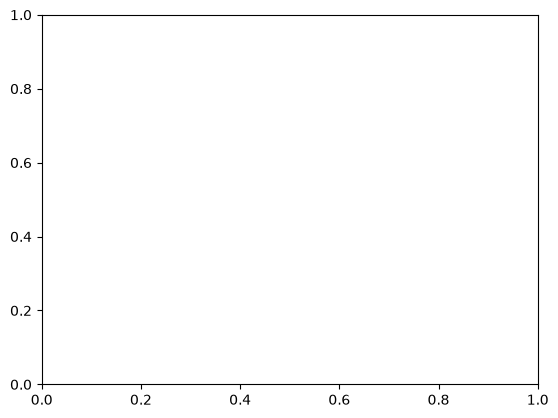

In [22]:
import matplotlib.pyplot as plt
from championship_teams.champions import champions
from championship_teams.utils import TeamWins, get_team_wins_in_first_n_games

fig, ax = plt.subplots()

all_records: list[TeamWins] = []
for champion in champions:
    wins_in_first_ten_games = get_team_wins_in_first_n_games(
        champion.abbreviation, champion.season, 10
    )
    all_records.append(wins_in_first_ten_games)

{'whiskers': [<matplotlib.lines.Line2D at 0xffff7d650590>,
 'caps': [<matplotlib.lines.Line2D at 0xffff7d650830>,
 'boxes': [<matplotlib.lines.Line2D at 0xffff7d650440>],
 'medians': [<matplotlib.lines.Line2D at 0xffff7d650ad0>],
 'fliers': [<matplotlib.lines.Line2D at 0xffff7d650d70>],
 'means': [<matplotlib.lines.Line2D at 0xffff7d650c20>]}

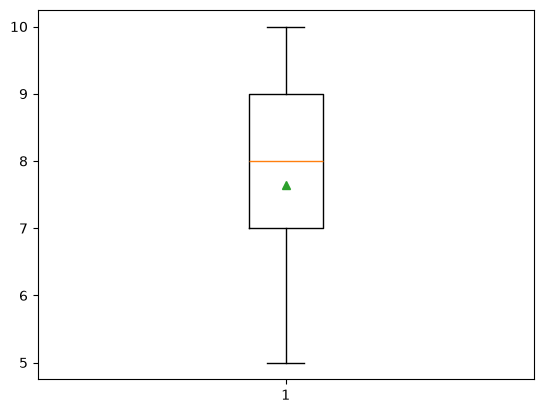

In [ ]:
plt.boxplot((x.wins for x in all_records), whis=(0, 100), showmeans=True)

In [ ]:
all

# only two teams were 5-5 and won the chip

[5,
 5,
 6,
 6,
 6,
 6,
 6,
 6,
 7,
 7,
 7,
 7,
 7,
 7,
 7,
 8,
 8,
 8,
 8,
 8,
 8,
 8,
 8,
 8,
 8,
 8,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 10,
 10]

In [23]:
from nba_api.stats.endpoints import commonallplayers

commonallplayers.CommonAllPlayers(timeout=30).get_data_frames()[0].head()


,PERSON_ID,DISPLAY_LAST_COMMA_FIRST,DISPLAY_FIRST_LAST,ROSTERSTATUS,FROM_YEAR,TO_YEAR,PLAYERCODE,PLAYER_SLUG,TEAM_ID,TEAM_CITY,TEAM_NAME,TEAM_ABBREVIATION,TEAM_CODE,TEAM_SLUG,GAMES_PLAYED_FLAG,OTHERLEAGUE_EXPERIENCE_CH
0,76001,"Abdelnaby, Alaa",Alaa Abdelnaby,0,1990,1994,HISTADD_alaa_abdelnaby,alaa_abdelnaby,0,,,,,NaN,Y,00
1,76002,"Abdul-Aziz, Zaid",Zaid Abdul-Aziz,0,1968,1977,HISTADD_zaid_abdul-aziz,zaid_abdul-aziz,0,,,,,NaN,Y,00
2,76003,"Abdul-Jabbar, Kareem",Kareem Abdul-Jabbar,0,1969,1988,HISTADD_kareem_abdul-jabbar,kareem_abdul-jabbar,0,,,,,NaN,Y,00
3,51,"Abdul-Rauf, Mahmoud",Mahmoud Abdul-Rauf,0,1990,2000,mahmoud_abdul-rauf,mahmoud_abdul-rauf,0,,,,,NaN,Y,00
4,1505,"Abdul-Wahad, Tariq",Tariq Abdul-Wahad,0,1997,2003,tariq_abdul-wahad,tariq_abdul-wahad,0,,,,,NaN,Y,00
